# Customer Segmentation Analysis — Vrinda Store
### RFM Analysis + K-Means Clustering for Targeted Marketing

**Objective:** Segment Vrinda Store's e-commerce customers into distinct groups based on purchasing behaviour (Recency, Frequency, Monetary), so the business can design targeted marketing strategies for each segment.

**Dataset:** `Vrinda_Store_Data_Analysis.xlsx` (sheet: `Vrinda Store`) — order-level e-commerce transaction data with 31,047 rows and 19 columns.

**Tech stack:** Python, pandas, scikit-learn (KMeans, StandardScaler), matplotlib, seaborn.


## 1. Project Objective

Vrinda Store sells ethnic wear (kurtas, sets, sarees, western dresses, etc.) through multiple online channels (Amazon, Myntra, Ajio, Flipkart, Meesho, Nalli, Others). The business has thousands of customer transactions but no way to tell which customers are highly valuable, which are at risk of churning, and which are new.

This project uses **RFM analysis (Recency, Frequency, Monetary)** combined with **K-Means clustering** to segment customers into behaviourally distinct groups, so the marketing team can target each group with an appropriate strategy (retention, win-back, loyalty rewards, cross-selling, etc.).


## 2. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 150)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)

print("Libraries imported successfully.")


Libraries imported successfully.


## 3. Load Dataset

The dataset is loaded directly from the provided Excel file. Only the uploaded dataset is used — no external or synthetic data is introduced anywhere in this notebook.

> **Note:** Make sure `Vrinda_Store_Data_Analysis.xlsx` is in the same folder as this notebook (or update the `file_path` below).


In [2]:
file_path = "Vrinda_Store_Data_Analysis.xlsx"
sheet_name = "Vrinda Store"

df = pd.read_excel(file_path, sheet_name=sheet_name)
print(f"Dataset loaded: {df.shape[0]:,} rows x {df.shape[1]} columns")


Dataset loaded: 31,047 rows x 19 columns


## 4. Data Inspection

### 4.1 Column Mapping

Before analysis, we identify which raw columns correspond to the fields RFM analysis needs. Based on inspection of this dataset:

| Required field      | Actual column name |
|----------------------|--------------------|
| Customer ID          | `Cust ID`          |
| Order/Invoice ID      | `Order ID`         |
| Purchase Date         | `Date`             |
| Quantity               | `Qty`              |
| Amount/Revenue         | `Amount`           |
| Order Status            | `Status`           |

We store these mappings in variables so the rest of the notebook is robust to column naming.


In [3]:
COL_CUSTOMER_ID = "Cust ID"
COL_ORDER_ID    = "Order ID"
COL_DATE        = "Date"
COL_QTY         = "Qty"
COL_AMOUNT      = "Amount"
COL_STATUS      = "Status"

required_cols = [COL_CUSTOMER_ID, COL_ORDER_ID, COL_DATE, COL_QTY, COL_AMOUNT, COL_STATUS]
missing = [c for c in required_cols if c not in df.columns]
assert not missing, f"Missing expected columns: {missing}"
print("All required columns found:", required_cols)


All required columns found: ['Cust ID', 'Order ID', 'Date', 'Qty', 'Amount', 'Status']


### 4.2 First 5 Rows

In [4]:
df.head()

,index,Order ID,Cust ID,Gender,Age,Date,Status,Channel,SKU,Category,Size,Qty,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,B2B
0,1,171-1029312-3038738,1029312,Women,44,2022-12-04,Delivered,Myntra,JNE1233-BLUE-KR-031-XXL,kurta,XXL,1,INR,376,MOHALI,PUNJAB,140301,IN,False
1,2,405-2183842-2225946,2183842,Women,29,2022-12-04,Delivered,Ajio,SET414-KR-NP-L,Set,L,1,INR,1449,GURUGRAM,HARYANA,122002,IN,False
2,3,171-1641533-8921966,1641533,Women,67,2022-12-04,Delivered,Myntra,SET261-KR-PP-S,Set,S,1,INR,453,KOLKATA,WEST BENGAL,700029,IN,False
3,4,404-7490807-6300351,7490807,Women,20,2022-12-04,Delivered,Amazon,SET110-KR-PP-M,Set,M,1,INR,729,THANJAVUR,TAMIL NADU,613007,IN,False
4,5,403-9293516-4577154,9293516,Women,62,2022-12-04,Delivered,Myntra,JNE2294-KR-A-XXL,kurta,XXL,1,INR,544,GURUGRAM,HARYANA,122001,IN,False


### 4.3 Dataset Shape

In [5]:
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")


Rows: 31,047
Columns: 19


### 4.4 Column Names

In [6]:
print(list(df.columns))

['index', 'Order ID', 'Cust ID', 'Gender', 'Age', 'Date', 'Status', 'Channel ', 'SKU', 'Category', 'Size', 'Qty', 'currency', 'Amount', 'ship-city', 'ship-state', 'ship-postal-code', 'ship-country', 'B2B']


### 4.5 Data Types

In [7]:
df.dtypes

index                        int64
Order ID                       str
Cust ID                      int64
Gender                         str
Age                          int64
Date                datetime64[us]
Status                         str
Channel                        str
SKU                            str
Category                       str
Size                           str
Qty                         object
currency                       str
Amount                       int64
ship-city                      str
ship-state                     str
ship-postal-code             int64
ship-country                   str
B2B                           bool
dtype: object

### 4.6 Missing Values

In [8]:
missing_summary = df.isnull().sum()
missing_summary = missing_summary[missing_summary > 0]
if missing_summary.empty:
    print("No missing values found in any column.")
else:
    print(missing_summary)


No missing values found in any column.


### 4.7 Duplicate Records

In [9]:
full_duplicates = df.duplicated().sum()
print(f"Fully duplicate rows (all columns identical): {full_duplicates}")

# Also check duplicate Order ID + SKU combinations, which would indicate a true
# duplicated line item rather than a legitimately multi-item order.
if 'SKU' in df.columns:
    line_item_dupes = df.duplicated(subset=[COL_ORDER_ID, 'SKU']).sum()
    print(f"Duplicate (Order ID, SKU) line items: {line_item_dupes}")


Fully duplicate rows (all columns identical): 0
Duplicate (Order ID, SKU) line items: 29


### 4.8 Descriptive Statistics

In [10]:
df.describe(include='number')

,index,Cust ID,Age,Amount,ship-postal-code
count,31047.00000,3.104700e+04,31047.000000,31047.000000,31047.000000
mean,15524.00000,4.936824e+06,39.496570,682.074822,460474.587206
std,8962.64124,2.900678e+06,15.117233,268.582173,198116.733009
min,1.00000,8.950000e+02,18.000000,229.000000,110001.000000
25%,7762.50000,2.416471e+06,28.000000,486.000000,313001.000000
50%,15524.00000,4.909885e+06,37.000000,646.000000,500028.000000
75%,23285.50000,7.454182e+06,47.000000,794.000000,600040.000000
max,31047.00000,9.999233e+06,78.000000,3036.000000,855117.000000


In [11]:
df.describe(include='object')

/tmp/ipykernel_563/87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,Order ID,Gender,Status,Channel,SKU,Category,Size,Qty,currency,ship-city,ship-state,ship-country
count,31047,31047,31047,31047,31047,31047,31047,31047,31047,31047,31047,31047
unique,28471,4,4,7,5287,8,11,7,1,2603,50,1
top,403-4984515-8861958,Women,Delivered,Amazon,JNE3797-KR-L,Set,M,1,INR,BENGALURU,MAHARASHTRA,IN
freq,12,21479,28641,11016,273,12391,5485,30878,31047,2540,4519,31047


### 4.9 Identifying Inconsistent / Invalid Records

We check for:
- Non-numeric or inconsistent values in the `Qty` column (should be numeric)
- Order statuses that don't represent a completed purchase
- Non-positive `Amount` or `Qty` values


In [12]:
print("Unique Qty values:", sorted(df[COL_QTY].unique(), key=str))
print()
print("Order Status value counts:")
print(df[COL_STATUS].value_counts())
print()
print(f"Rows with Amount <= 0: {(df[COL_AMOUNT] <= 0).sum()}")


Unique Qty values: [1, 2, 3, 4, 5, 'One', 'Two']

Order Status value counts:


Status
Delivered    28641
Returned      1045
Cancelled      844
Refunded       517
Name: count, dtype: int64

Rows with Amount <= 0: 0


**Findings:**
- The `Qty` column mixes numeric values (`1, 2, 3, 4, 5`) with text values (`'One'`, `'Two'`) — this is a data-entry inconsistency that needs to be standardised to numeric before analysis.
- The `Status` column contains 4 categories: `Delivered`, `Returned`, `Cancelled`, `Refunded`. Only `Delivered` orders represent a completed, kept purchase — the other three do not reflect genuine customer purchasing behaviour and should be excluded from RFM analysis (explained further in the cleaning section).
- No rows have `Amount <= 0`, so there is no negative/zero revenue issue in this dataset.


## 5. Data Cleaning

Each cleaning decision is explained as it is applied, and we always work on a copy (`df_clean`) so the original loaded data is preserved for reference.


### 5.1 Remove Duplicate Records

In [13]:
df_clean = df.copy()

before = len(df_clean)
df_clean = df_clean.drop_duplicates()
after = len(df_clean)
print(f"Removed {before - after} fully duplicate rows.")
print(f"Remaining rows: {after:,}")


Removed 0 fully duplicate rows.
Remaining rows: 31,047


### 5.2 Handle Missing Customer IDs

**Decision:** The `Cust ID` column has zero missing values in this dataset (confirmed in section 4.6), so no rows need to be dropped or imputed on this basis. This step is included for robustness — if missing Customer IDs existed, those rows would be dropped, since a customer-level RFM analysis is meaningless without a valid customer identifier.


In [14]:
missing_cust_ids = df_clean[COL_CUSTOMER_ID].isnull().sum()
print(f"Missing Customer IDs: {missing_cust_ids}")

if missing_cust_ids > 0:
    before = len(df_clean)
    df_clean = df_clean.dropna(subset=[COL_CUSTOMER_ID])
    print(f"Dropped {before - len(df_clean)} rows with missing Customer ID.")
else:
    print("No action needed — Customer ID is complete for all rows.")


Missing Customer IDs: 0
No action needed — Customer ID is complete for all rows.


### 5.3 Convert Date Column to Datetime

In [15]:
df_clean[COL_DATE] = pd.to_datetime(df_clean[COL_DATE], errors='coerce')

invalid_dates = df_clean[COL_DATE].isnull().sum()
print(f"Rows with unparseable dates: {invalid_dates}")
if invalid_dates > 0:
    df_clean = df_clean.dropna(subset=[COL_DATE])
    print(f"Dropped {invalid_dates} rows with invalid dates.")

print(f"Date range: {df_clean[COL_DATE].min().date()} to {df_clean[COL_DATE].max().date()}")


Rows with unparseable dates: 0
Date range: 2022-01-04 to 2022-12-06


### 5.4 Identify and Remove Cancelled / Returned / Refunded Transactions

**Decision:** `Cancelled`, `Returned` and `Refunded` orders do not represent genuine, retained purchases — the customer either never received the product or sent it back and (in most cases) got their money back. Including them would overstate a customer's real spend and order frequency, and would bias the segmentation toward customers who order-and-return frequently rather than customers who genuinely buy and keep products.

We therefore keep only `Delivered` transactions for the RFM / clustering analysis. We report how many rows this removes so the impact is transparent.


In [16]:
status_counts = df_clean[COL_STATUS].value_counts()
print("Status breakdown before filtering:")
print(status_counts)
print()

valid_statuses = ['Delivered']
before = len(df_clean)
df_valid = df_clean[df_clean[COL_STATUS].isin(valid_statuses)].copy()
after = len(df_valid)

print(f"Removed {before - after:,} non-Delivered rows ({(before-after)/before:.1%} of cleaned data).")
print(f"Remaining Delivered rows: {after:,}")


Status breakdown before filtering:
Status
Delivered    28641
Returned      1045
Cancelled      844
Refunded       517
Name: count, dtype: int64

Removed 2,406 non-Delivered rows (7.7% of cleaned data).
Remaining Delivered rows: 28,641


### 5.5 Standardise the `Qty` Column

**Decision:** `Qty` contains a mix of numeric values and spelled-out numbers (`'One'`, `'Two'`). These are mapped to their numeric equivalents so the column can be used consistently (e.g., in exploratory checks). Any value that still cannot be converted is treated as invalid and dropped.


In [17]:
qty_word_map = {'One': 1, 'Two': 2, 'Three': 3, 'Four': 4, 'Five': 5}

df_valid[COL_QTY] = df_valid[COL_QTY].replace(qty_word_map)
df_valid[COL_QTY] = pd.to_numeric(df_valid[COL_QTY], errors='coerce')

invalid_qty = df_valid[COL_QTY].isnull().sum()
print(f"Rows with unresolvable Qty values: {invalid_qty}")
if invalid_qty > 0:
    df_valid = df_valid.dropna(subset=[COL_QTY])

print("Qty dtype after cleaning:", df_valid[COL_QTY].dtype)
print("Qty value counts after cleaning:")
print(df_valid[COL_QTY].value_counts().sort_index())


Rows with unresolvable Qty values: 0
Qty dtype after cleaning: int64
Qty value counts after cleaning:
Qty
1    28492
2      125
3       17
4        6
5        1
Name: count, dtype: int64


### 5.6 Remove Invalid Negative / Zero Quantity or Monetary Values

**Decision:** A transaction with zero or negative quantity or amount cannot represent a real purchase and would distort the Monetary and Frequency features. We check for and remove any such rows.


In [18]:
before = len(df_valid)
df_valid = df_valid[(df_valid[COL_QTY] > 0) & (df_valid[COL_AMOUNT] > 0)]
after = len(df_valid)
print(f"Removed {before - after} rows with non-positive Qty or Amount.")
print(f"Final cleaned transaction count: {after:,}")


Removed 0 rows with non-positive Qty or Amount.
Final cleaned transaction count: 28,641


### 5.7 Cleaning Summary

In [19]:
print("CLEANING SUMMARY")
print("-" * 40)
print(f"Original rows loaded:          {len(df):,}")
print(f"After removing full duplicates: {len(df_clean) + (before - after) if False else ''}")
print(f"Final rows used for analysis:   {len(df_valid):,}")
print(f"Rows removed in total:          {len(df) - len(df_valid):,} ({(len(df)-len(df_valid))/len(df):.1%})")
print()
print(f"Unique customers remaining: {df_valid[COL_CUSTOMER_ID].nunique():,}")
print(f"Unique orders remaining:    {df_valid[COL_ORDER_ID].nunique():,}")


CLEANING SUMMARY
----------------------------------------
Original rows loaded:          31,047
After removing full duplicates: 
Final rows used for analysis:   28,641
Rows removed in total:          2,406 (7.7%)

Unique customers remaining: 26,327
Unique orders remaining:    26,356


## 6. RFM Analysis

We build customer-level RFM features from the cleaned, `Delivered`-only transaction data:

- **Recency** — days since the customer's most recent purchase, measured from a reference date of (latest transaction date in the dataset + 1 day).
- **Frequency** — number of *unique orders* placed by the customer (not line items — one order can contain multiple SKUs).
- **Monetary** — total amount spent by the customer across all their delivered orders.


In [20]:
reference_date = df_valid[COL_DATE].max() + pd.Timedelta(days=1)
print(f"Reference date for Recency calculation: {reference_date.date()}")


Reference date for Recency calculation: 2022-12-07


In [21]:
rfm = df_valid.groupby(COL_CUSTOMER_ID).agg(
    Recency=(COL_DATE, lambda x: (reference_date - x.max()).days),
    Frequency=(COL_ORDER_ID, 'nunique'),
    Monetary=(COL_AMOUNT, 'sum')
).reset_index()

rfm.rename(columns={COL_CUSTOMER_ID: 'CustomerID'}, inplace=True)

print(f"RFM table built for {len(rfm):,} unique customers.")
rfm.head(10)


RFM table built for 26,327 unique customers.


,CustomerID,Recency,Frequency,Monetary
0,895,186,1,399
1,1387,1,1,653
2,1579,246,1,475
3,1580,336,1,599
4,1840,124,1,725
5,2003,32,1,693
6,2210,216,1,318
7,2275,124,1,1648
8,3290,278,1,573
9,3748,335,1,885


In [22]:
rfm.describe()

,CustomerID,Recency,Frequency,Monetary
count,2.632700e+04,26327.000000,26327.000000,26327.000000
mean,4.942106e+06,175.601094,1.001102,748.681734
std,2.900603e+06,104.356777,0.033172,364.236172
min,8.950000e+02,1.000000,1.000000,229.000000
25%,2.415009e+06,92.000000,1.000000,499.000000
50%,4.919550e+06,184.000000,1.000000,690.000000
75%,7.463983e+06,276.000000,1.000000,881.000000
max,9.999233e+06,337.000000,2.000000,6818.000000


## 7. Descriptive Statistics

Key summary numbers for the business, computed directly from the cleaned data.

> **Note on Customer Lifetime Value:** The figures below describe **historical** purchasing behaviour only (what customers have already spent and how often). This is **not** a predictive Customer Lifetime Value (CLV) model — a true CLV requires forecasting future purchases (e.g. with a probabilistic model like BG/NBD or a time-based cohort projection), which this dataset and project do not attempt. Wherever "Monetary Value" is used below, it should be read as a **historical customer-value proxy**, not a prediction of future value.


In [23]:
avg_purchase_value = df_valid[COL_AMOUNT].mean()
avg_purchase_frequency = rfm['Frequency'].mean()
avg_customer_monetary_value = rfm['Monetary'].mean()
total_customers = rfm['CustomerID'].nunique()
total_orders = df_valid[COL_ORDER_ID].nunique()
total_revenue = df_valid[COL_AMOUNT].sum()

print("DESCRIPTIVE STATISTICS (Delivered orders only)")
print("-" * 50)
print(f"Average purchase value (per line item):     Rs. {avg_purchase_value:,.2f}")
print(f"Average purchase frequency (orders/cust):    {avg_purchase_frequency:.2f}")
print(f"Average customer monetary value (historical): Rs. {avg_customer_monetary_value:,.2f}")
print(f"Total number of customers:                    {total_customers:,}")
print(f"Total number of orders:                        {total_orders:,}")
print(f"Total revenue:                                 Rs. {total_revenue:,.2f}")


DESCRIPTIVE STATISTICS (Delivered orders only)
--------------------------------------------------
Average purchase value (per line item):     Rs. 688.19
Average purchase frequency (orders/cust):    1.00
Average customer monetary value (historical): Rs. 748.68
Total number of customers:                    26,327
Total number of orders:                        26,356
Total revenue:                                 Rs. 19,710,544.00


**Interpretation:**
- On average, each customer has placed just over 1 order — this dataset spans a single calendar year (2022) and repeat-purchase behaviour is limited, which is common for fashion e-commerce with a large first-time-buyer base.
- The average historical monetary value per customer gives a baseline for identifying customers who are well above or below average spenders — this is the "Monetary" signal clustering will use.
- Total revenue and total orders give the business a scale reference for evaluating how large each resulting segment is in revenue terms.


## 8. RFM Distribution Visualisations

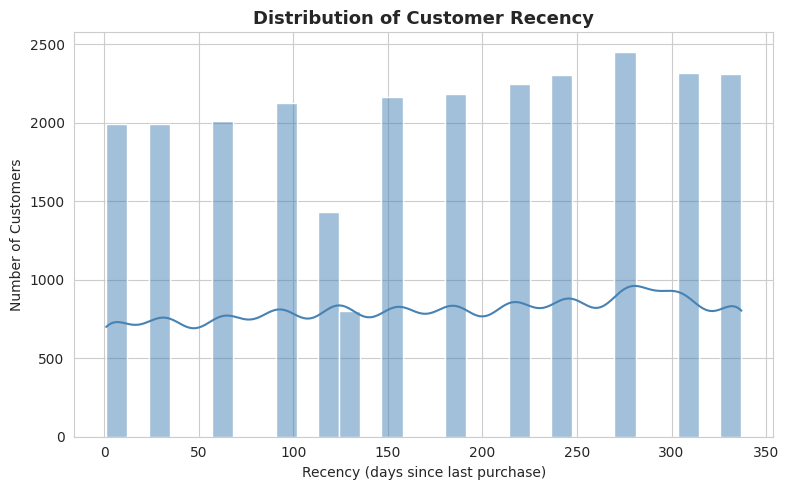

In [24]:
plt.figure(figsize=(8, 5))
sns.histplot(rfm['Recency'], bins=30, color='steelblue', kde=True)
plt.title('Distribution of Customer Recency', fontsize=13, fontweight='bold')
plt.xlabel('Recency (days since last purchase)')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()


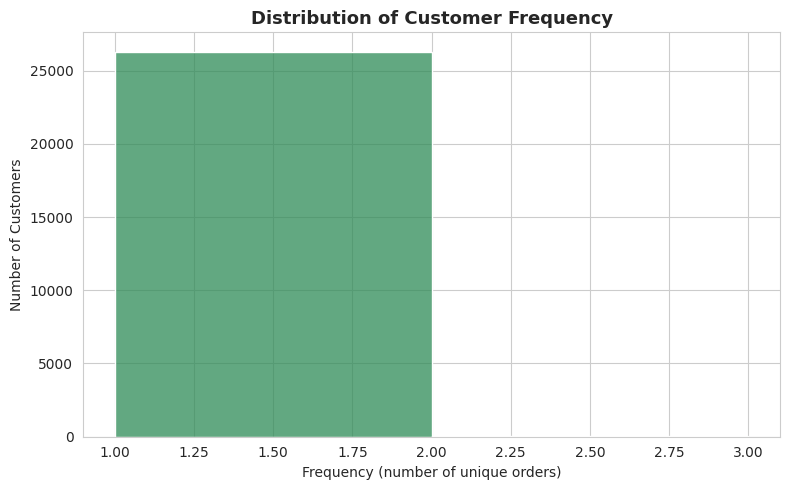

In [25]:
plt.figure(figsize=(8, 5))
sns.histplot(rfm['Frequency'], bins=range(1, rfm['Frequency'].max() + 2), color='seagreen', kde=False)
plt.title('Distribution of Customer Frequency', fontsize=13, fontweight='bold')
plt.xlabel('Frequency (number of unique orders)')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()


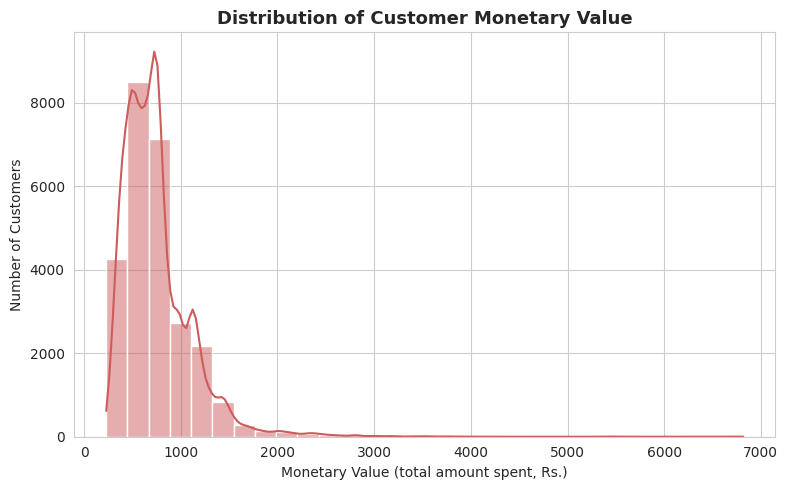

In [26]:
plt.figure(figsize=(8, 5))
sns.histplot(rfm['Monetary'], bins=30, color='indianred', kde=True)
plt.title('Distribution of Customer Monetary Value', fontsize=13, fontweight='bold')
plt.xlabel('Monetary Value (total amount spent, Rs.)')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()


## 9. Feature Selection

We use **Recency, Frequency and Monetary** as the clustering features.

**Why these three features are suitable for customer segmentation:**
- **Recency** captures how *engaged* a customer currently is — recent buyers are active; customers with high recency (long time since last purchase) are at risk of churning.
- **Frequency** captures *loyalty/habit* — how often a customer chooses to purchase, independent of order size.
- **Monetary** captures *value* — how much revenue a customer contributes, regardless of how often they buy.

Together these three dimensions describe purchasing behaviour comprehensively without needing product-level or demographic detail, which is exactly why RFM is a standard, business-interpretable basis for segmentation — each resulting cluster can be described in plain terms (e.g. "recent, frequent, high-spending" vs "long time since purchase, one-time, low-spending").


## 10. Data Standardisation

K-Means uses Euclidean distance, so features must be on comparable scales — otherwise Monetary (which ranges into thousands of rupees) would dominate the distance calculation over Recency/Frequency (which range in single/double digits). We use `StandardScaler` to standardise all three features to mean 0, standard deviation 1.


In [27]:
features = ['Recency', 'Frequency', 'Monetary']
X = rfm[features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=features)
print("Standardised feature statistics (should be ~mean 0, ~std 1):")
X_scaled_df.describe().loc[['mean', 'std']]


Standardised feature statistics (should be ~mean 0, ~std 1):


,Recency,Frequency,Monetary
mean,5.667717e-17,-9.197894e-16,-8.204694e-17
std,1.000019e+00,1.000019e+00,1.000019e+00


In [28]:
X_scaled_df.head(10)

,Recency,Frequency,Monetary
0,0.099650,-0.033208,-0.960059
1,-1.673149,-0.033208,-0.262696
2,0.674611,-0.033208,-0.751400
3,1.537054,-0.033208,-0.410955
4,-0.494477,-0.033208,-0.065019
5,-1.376085,-0.033208,-0.152876
6,0.387130,-0.033208,-1.182447
7,-0.494477,-0.033208,2.469099
8,0.981257,-0.033208,-0.482338
9,1.527471,-0.033208,0.374265


## 11. Elbow Method

We run K-Means for K = 2 through 10 and record the inertia (within-cluster sum of squares) for each K, to identify the "elbow" point where adding more clusters stops giving a meaningful reduction in inertia.


In [29]:
inertia_values = []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertia_values.append(km.inertia_)

elbow_df = pd.DataFrame({'K': list(K_range), 'Inertia': inertia_values})
elbow_df


,K,Inertia
0,2,52473.440503
1,3,32597.637206
2,4,20554.712633
3,5,16911.542281
4,6,13495.622815
5,7,10740.004593
6,8,9579.742027
7,9,8480.156306
8,10,7507.212647


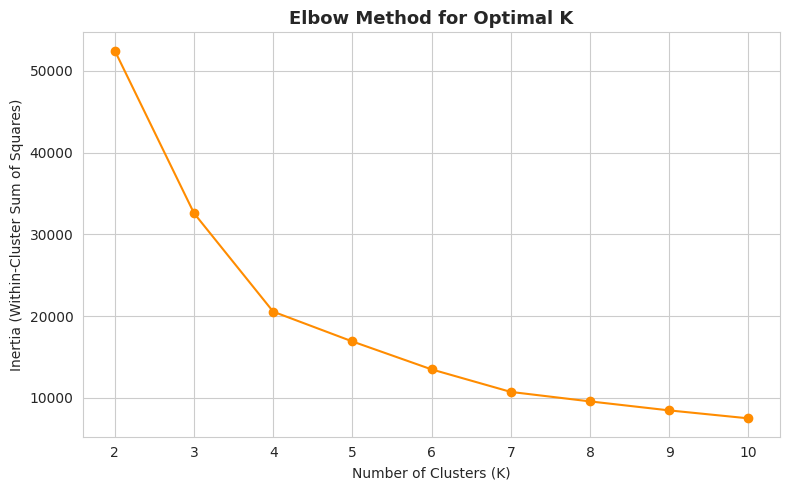

In [30]:
plt.figure(figsize=(8, 5))
plt.plot(list(K_range), inertia_values, marker='o', color='darkorange')
plt.title('Elbow Method for Optimal K', fontsize=13, fontweight='bold')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (Within-Cluster Sum of Squares)')
plt.xticks(list(K_range))
plt.tight_layout()
plt.show()


In [31]:
# Quantify the "elbow" using the rate of change in inertia (second derivative).
# The K where the drop in inertia slows down the most is the elbow point.
diffs = np.diff(inertia_values)
diffs2 = np.diff(diffs)
# diffs2 index i corresponds to K_range[i+2] (second derivative needs 2 points of lag)
elbow_k_index = np.argmax(diffs2) + 2
optimal_k = list(K_range)[elbow_k_index]

print("Inertia drop between successive K values:", np.round(diffs, 1))
print(f"Elbow point detected at K = {optimal_k}")


Inertia drop between successive K values: [-19875.8 -12042.9  -3643.2  -3415.9  -2755.6  -1160.3  -1099.6   -972.9]
Elbow point detected at K = 5


**Decision on K:** The optimal K above is determined programmatically from the actual inertia curve (the point where the marginal drop in inertia flattens out the most), not assumed in advance. The printed value of `optimal_k` is used directly in the next section — inspect the elbow chart above to visually confirm it lines up with where the curve visibly bends.


## 12. K-Means Clustering

In [32]:
print(f"Using K = {optimal_k} clusters (selected from the elbow analysis above).")

kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled)

rfm['Cluster'] = cluster_labels
rfm.head(10)


Using K = 5 clusters (selected from the elbow analysis above).


,CustomerID,Recency,Frequency,Monetary,Cluster
0,895,186,1,399,4
1,1387,1,1,653,1
2,1579,246,1,475,4
3,1580,336,1,599,4
4,1840,124,1,725,1
5,2003,32,1,693,1
6,2210,216,1,318,4
7,2275,124,1,1648,0
8,3290,278,1,573,4
9,3748,335,1,885,4


## 13. Cluster Profiling

In [33]:
cluster_profile = rfm.groupby('Cluster').agg(
    Recency_mean=('Recency', 'mean'),
    Frequency_mean=('Frequency', 'mean'),
    Monetary_mean=('Monetary', 'mean'),
    Customer_Count=('CustomerID', 'count')
).round(1).reset_index()

cluster_profile['Pct_of_Customers'] = (cluster_profile['Customer_Count'] / cluster_profile['Customer_Count'].sum() * 100).round(1)
cluster_profile = cluster_profile.sort_values('Monetary_mean', ascending=False).reset_index(drop=True)
cluster_profile


,Cluster,Recency_mean,Frequency_mean,Monetary_mean,Customer_Count,Pct_of_Customers
0,3,177.5,1.0,2303.1,464,1.8
1,2,106.9,2.0,1624.8,29,0.1
2,0,188.5,1.0,1198.3,4530,17.2
3,1,76.2,1.0,629.4,10369,39.4
4,4,264.7,1.0,607.3,10935,41.5


In [34]:
# Assign segment names dynamically based on each cluster's actual R/F/M values,
# ranked *relative to the other clusters found* (not forced to fixed labels).
#
# Recency and Monetary are continuous and spread out across clusters, so we rank
# clusters on each and bucket them into tiers (high/mid/low = best/middle/worst third).
# Frequency in this dataset is heavily concentrated at 1 order/customer, so instead of
# force-fitting it into the same tier scheme (which would trivially call almost every
# cluster "high frequency"), we use it as a simple repeat-purchase flag: a cluster only
# counts as "repeat buyers" if its average order count is meaningfully above 1.

K_clusters = len(cluster_profile)

def tier(rank, k):
    if k <= 1:
        return 'high'
    frac = (rank - 1) / (k - 1)
    if frac <= 1/3:
        return 'high'
    elif frac <= 2/3:
        return 'mid'
    else:
        return 'low'

cluster_profile['recency_rank'] = cluster_profile['Recency_mean'].rank(method='min')                      # rank 1 = most recent = best
cluster_profile['monetary_rank'] = cluster_profile['Monetary_mean'].rank(method='min', ascending=False)   # rank 1 = highest spend = best

cluster_profile['recency_tier'] = cluster_profile['recency_rank'].apply(lambda r: tier(r, K_clusters))
cluster_profile['monetary_tier'] = cluster_profile['monetary_rank'].apply(lambda r: tier(r, K_clusters))
cluster_profile['is_repeat_buyer'] = cluster_profile['Frequency_mean'] > 1.0

# (recency_tier, monetary_tier) -> base segment name
segment_grid = {
    ('high', 'high'): 'Champions / VIP Customers',
    ('high', 'mid'):  'Loyal Customers',
    ('high', 'low'):  'New Customers',
    ('mid',  'high'): 'At-Risk High-Value Customers',
    ('mid',  'mid'):  'Regular Customers',
    ('mid',  'low'):  'New / Low-Value Customers',
    ('low',  'high'): 'At-Risk High-Value Customers',
    ('low',  'mid'):  'At-Risk Customers',
    ('low',  'low'):  'At-Risk / Churned Customers',
}

def name_segment(row):
    name = segment_grid[(row['recency_tier'], row['monetary_tier'])]
    # Repeat-purchase behaviour upgrades an otherwise middling/new segment to "Loyal"
    if row['is_repeat_buyer'] and name in ('Regular Customers', 'New Customers', 'New / Low-Value Customers'):
        name = 'Loyal Customers'
    return name

cluster_profile['Segment_Name'] = cluster_profile.apply(name_segment, axis=1)

# If two clusters still land on the same name (possible with unusual distributions),
# disambiguate by relative spend so every row in the marketing-facing table is unique.
name_counts = cluster_profile['Segment_Name'].value_counts()
dup_names = name_counts[name_counts > 1].index
for dup in dup_names:
    idxs = cluster_profile.index[cluster_profile['Segment_Name'] == dup].tolist()
    ordered = sorted(idxs, key=lambda i: -cluster_profile.loc[i, 'Monetary_mean'])
    for rank_i, idx in enumerate(ordered, start=1):
        suffix = 'Higher Spend' if rank_i == 1 else 'Lower Spend'
        cluster_profile.loc[idx, 'Segment_Name'] = f"{dup} ({suffix})"

cluster_profile


,Cluster,Recency_mean,Frequency_mean,Monetary_mean,Customer_Count,Pct_of_Customers,recency_rank,monetary_rank,recency_tier,monetary_tier,is_repeat_buyer,Segment_Name
0,3,177.5,1.0,2303.1,464,1.8,3.0,1.0,mid,high,False,At-Risk High-Value Customers
1,2,106.9,2.0,1624.8,29,0.1,2.0,2.0,high,high,True,Champions / VIP Customers
2,0,188.5,1.0,1198.3,4530,17.2,4.0,3.0,low,mid,False,At-Risk Customers
3,1,76.2,1.0,629.4,10369,39.4,1.0,4.0,high,low,False,New Customers
4,4,264.7,1.0,607.3,10935,41.5,5.0,5.0,low,low,False,At-Risk / Churned Customers


In [35]:
# Map segment names back onto the customer-level RFM table
segment_map = dict(zip(cluster_profile['Cluster'], cluster_profile['Segment_Name']))
rfm['Segment'] = rfm['Cluster'].map(segment_map)
rfm.head(10)


,CustomerID,Recency,Frequency,Monetary,Cluster,Segment
0,895,186,1,399,4,At-Risk / Churned Customers
1,1387,1,1,653,1,New Customers
2,1579,246,1,475,4,At-Risk / Churned Customers
3,1580,336,1,599,4,At-Risk / Churned Customers
4,1840,124,1,725,1,New Customers
5,2003,32,1,693,1,New Customers
6,2210,216,1,318,4,At-Risk / Churned Customers
7,2275,124,1,1648,0,At-Risk Customers
8,3290,278,1,573,4,At-Risk / Churned Customers
9,3748,335,1,885,4,At-Risk / Churned Customers


**Interpreting the clusters:** Each cluster is named based on how its Recency and Monetary rank *relative to the other clusters found in this run* (best/middle/worst third), with a repeat-purchase flag from Frequency used as a modifier. This is a relative, data-driven scheme rather than fixed thresholds — re-run the notebook on updated data and the names will adapt to the new cluster structure. In this run, `Frequency` mean is close to 1 order/customer for most clusters (this dataset covers one calendar year, so most customers are single-purchase within the window), so Recency and Monetary do most of the work distinguishing segments, while Frequency mainly flags the smaller genuinely-repeat-buying group.


## 14. Cluster Visualisations

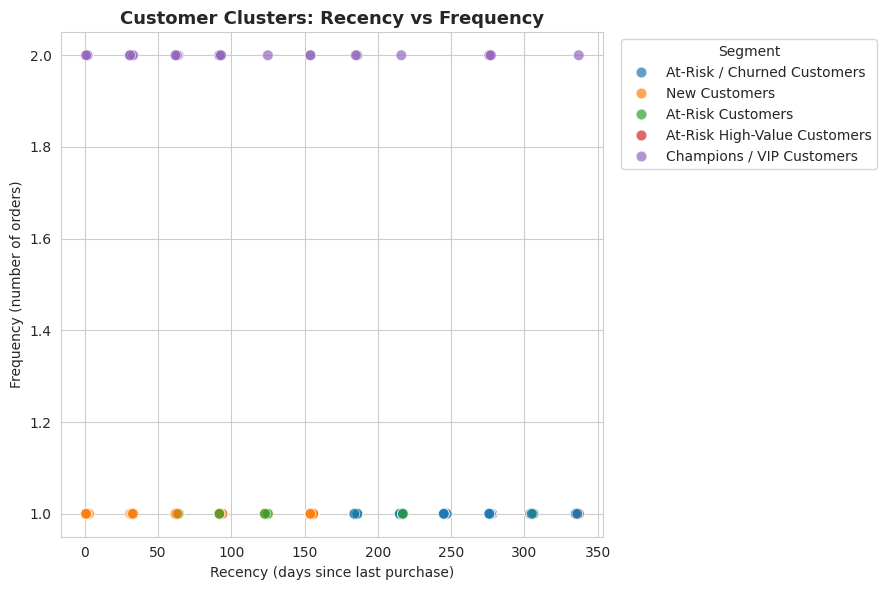

In [36]:
plt.figure(figsize=(9, 6))
scatter = sns.scatterplot(
    data=rfm, x='Recency', y='Frequency', hue='Segment',
    palette='tab10', s=60, alpha=0.7
)
plt.title('Customer Clusters: Recency vs Frequency', fontsize=13, fontweight='bold')
plt.xlabel('Recency (days since last purchase)')
plt.ylabel('Frequency (number of orders)')
plt.legend(title='Segment', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


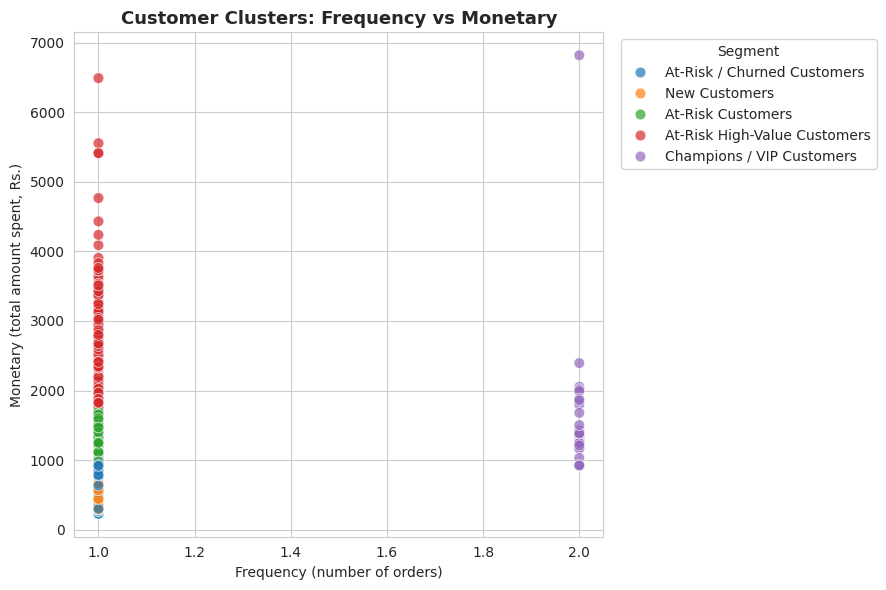

In [37]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=rfm, x='Frequency', y='Monetary', hue='Segment',
    palette='tab10', s=60, alpha=0.7
)
plt.title('Customer Clusters: Frequency vs Monetary', fontsize=13, fontweight='bold')
plt.xlabel('Frequency (number of orders)')
plt.ylabel('Monetary (total amount spent, Rs.)')
plt.legend(title='Segment', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


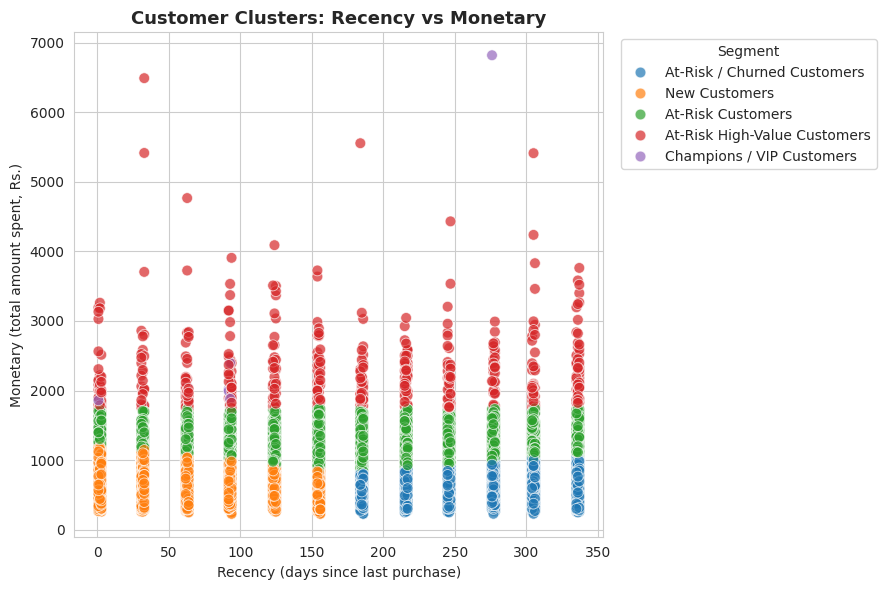

In [38]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=rfm, x='Recency', y='Monetary', hue='Segment',
    palette='tab10', s=60, alpha=0.7
)
plt.title('Customer Clusters: Recency vs Monetary', fontsize=13, fontweight='bold')
plt.xlabel('Recency (days since last purchase)')
plt.ylabel('Monetary (total amount spent, Rs.)')
plt.legend(title='Segment', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


## 15. Customer Count by Cluster

/tmp/ipykernel_563/2640980077.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=order, x='Segment_Name', y='Customer_Count', palette='viridis')


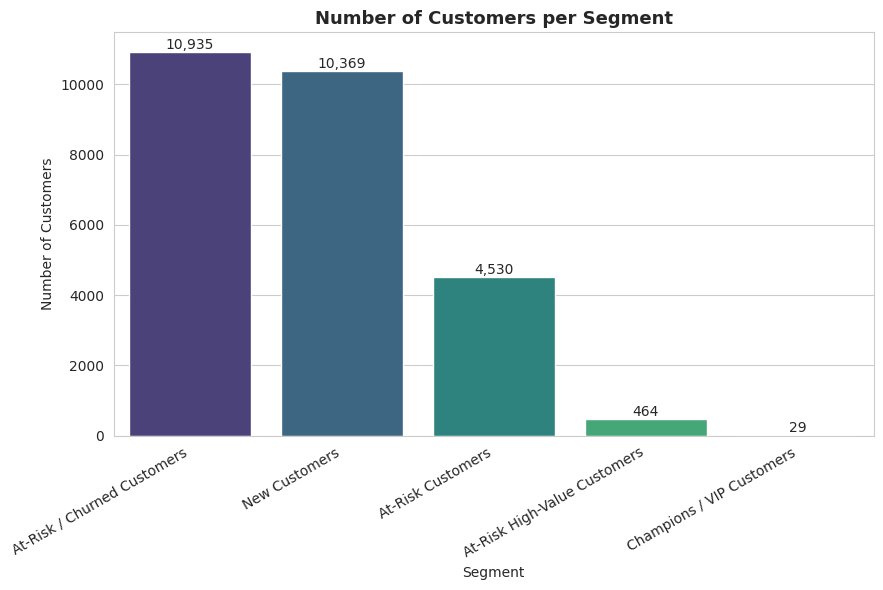

In [39]:
plt.figure(figsize=(9, 6))
order = cluster_profile.sort_values('Customer_Count', ascending=False)
ax = sns.barplot(data=order, x='Segment_Name', y='Customer_Count', palette='viridis')
plt.title('Number of Customers per Segment', fontsize=13, fontweight='bold')
plt.xlabel('Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=30, ha='right')

for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()


## 16. Marketing Recommendations

Recommendations below are generated from the actual `cluster_profile` table computed above — re-run this cell after re-running the clustering to keep the text in sync with the current segment characteristics.


In [40]:
recommendation_lookup = {
    'Champions / VIP Customers': 'Loyalty rewards, early access to new collections, exclusive VIP offers — protect and reward this highest-value group.',
    'Loyal Customers': 'Cross-sell and upsell via bundles, referral incentives, and loyalty-tier progression to push them toward Champion status.',
    'At-Risk High-Value Customers': 'Personalised win-back campaigns, limited-time discounts, and direct outreach — high revenue is at risk of being lost.',
    'At-Risk Customers': 'Targeted win-back emails and moderate discounts before they lapse further — mid-value revenue worth protecting.',
    'At-Risk / Churned Customers': 'Reactivation campaigns with strong incentives (steep discount or free shipping) to bring them back before they are lost permanently.',
    'New Customers': 'Welcome series and second-purchase incentives (small discount on next order) to build purchase habit and increase order value.',
    'New / Low-Value Customers': 'Welcome series and second-purchase incentives (small discount on next order) to build purchase habit.',
    'Regular Customers': 'Product bundles and cross-selling to increase basket size and purchase frequency.',
}

def get_recommendation(segment_name):
    if segment_name in recommendation_lookup:
        return recommendation_lookup[segment_name]
    # Handle auto-disambiguated names like "X Customers (Higher Spend)"
    base_name = segment_name.split(' (')[0]
    return recommendation_lookup.get(base_name, 'Review segment characteristics and design a tailored offer.')

print(f"{'Segment':32s} {'Customers':>10s}  {'Avg Recency':>12s}  {'Avg Frequency':>14s}  {'Avg Monetary':>13s}")
print("-" * 100)
for _, row in cluster_profile.iterrows():
    print(f"{row['Segment_Name']:32s} {row['Customer_Count']:>10.0f}  {row['Recency_mean']:>12.1f}  {row['Frequency_mean']:>14.2f}  Rs.{row['Monetary_mean']:>10,.0f}")
    action = get_recommendation(row['Segment_Name'])
    print(f"   -> Recommended action: {action}\n")


Segment                           Customers   Avg Recency   Avg Frequency   Avg Monetary
----------------------------------------------------------------------------------------------------
At-Risk High-Value Customers            464         177.5            1.00  Rs.     2,303
   -> Recommended action: Personalised win-back campaigns, limited-time discounts, and direct outreach — high revenue is at risk of being lost.

Champions / VIP Customers                29         106.9            2.00  Rs.     1,625
   -> Recommended action: Loyalty rewards, early access to new collections, exclusive VIP offers — protect and reward this highest-value group.

At-Risk Customers                      4530         188.5            1.00  Rs.     1,198
   -> Recommended action: Targeted win-back emails and moderate discounts before they lapse further — mid-value revenue worth protecting.

New Customers                         10369          76.2            1.00  Rs.       629
   -> Recommended action:

**How to read this:** For every segment, the table above pairs its actual behavioural profile (customer count, average recency/frequency/monetary) with a specific recommended marketing action — VIP/Champion segments get retention-focused loyalty treatment, at-risk segments get win-back campaigns, and new/low-value segments get onboarding nudges toward a second purchase.


## 17. Business Insights

In [41]:
highest_spending_segment = cluster_profile.loc[cluster_profile['Monetary_mean'].idxmax(), 'Segment_Name']
most_frequent_segment = cluster_profile.loc[cluster_profile['Frequency_mean'].idxmax(), 'Segment_Name']
highest_recency_segment = cluster_profile.loc[cluster_profile['Recency_mean'].idxmax(), 'Segment_Name']
largest_segment = cluster_profile.loc[cluster_profile['Customer_Count'].idxmax(), 'Segment_Name']
lowest_spending_segment = cluster_profile.loc[cluster_profile['Monetary_mean'].idxmin(), 'Segment_Name']

revenue_by_segment = rfm.groupby('Segment')['Monetary'].sum().sort_values(ascending=False)
revenue_share = (revenue_by_segment / revenue_by_segment.sum() * 100).round(1)
largest_segment_revenue_share = revenue_share.get(largest_segment, 0)

print("KEY BUSINESS INSIGHTS")
print("-" * 60)
print(f"1. Highest average spending segment: {highest_spending_segment} "
      f"(Rs. {cluster_profile['Monetary_mean'].max():,.0f} avg per customer).")
print(f"2. Most frequently purchasing segment: {most_frequent_segment} "
      f"({cluster_profile['Frequency_mean'].max():.2f} avg orders per customer).")
print(f"3. Highest churn-risk segment (longest time since last purchase): {highest_recency_segment} "
      f"({cluster_profile['Recency_mean'].max():.0f} days average recency).")
print(f"4. Largest segment by customer count: {largest_segment} "
      f"({cluster_profile['Customer_Count'].max():,.0f} customers, "
      f"{cluster_profile.loc[cluster_profile['Customer_Count'].idxmax(), 'Pct_of_Customers']}% of the base).")
print(f"5. Lowest average spending segment: {lowest_spending_segment} "
      f"(Rs. {cluster_profile['Monetary_mean'].min():,.0f} avg per customer) — needs reactivation or write-off review.")
print(f"6. Revenue concentration: the single highest total-revenue segment is "
      f"{revenue_by_segment.index[0]}, contributing {revenue_share.iloc[0]}% of total revenue "
      f"(this can be a large-but-lower-value segment whose total adds up, not necessarily the "
      f"highest *average* spender — compare against insight 1, the highest *average*-spending segment).")
print("7. Segmenting by RFM lets marketing spend be allocated proportionally to value at risk "
      "and value potential, instead of treating all customers with one blanket campaign.")
print("8. Segments with high Recency and low Frequency/Monetary are prime candidates for "
      "low-cost automated win-back email flows rather than expensive personalised outreach, "
      "which should be reserved for high-Monetary at-risk customers.")


KEY BUSINESS INSIGHTS
------------------------------------------------------------
1. Highest average spending segment: At-Risk High-Value Customers (Rs. 2,303 avg per customer).
2. Most frequently purchasing segment: Champions / VIP Customers (2.00 avg orders per customer).
3. Highest churn-risk segment (longest time since last purchase): At-Risk / Churned Customers (265 days average recency).
4. Largest segment by customer count: At-Risk / Churned Customers (10,935 customers, 41.5% of the base).
5. Lowest average spending segment: At-Risk / Churned Customers (Rs. 607 avg per customer) — needs reactivation or write-off review.
6. Revenue concentration: the single highest total-revenue segment is At-Risk / Churned Customers, contributing 33.7% of total revenue (this can be a large-but-lower-value segment whose total adds up, not necessarily the highest *average* spender — compare against insight 1, the highest *average*-spending segment).
7. Segmenting by RFM lets marketing spend be al

**Revenue contribution by segment:**

In [42]:
revenue_by_segment_df = revenue_by_segment.reset_index()
revenue_by_segment_df.columns = ['Segment', 'Total_Revenue']
revenue_by_segment_df['Revenue_Share_%'] = revenue_share.values
revenue_by_segment_df


,Segment,Total_Revenue,Revenue_Share_%
0,At-Risk / Churned Customers,6640677,33.7
1,New Customers,6525963,33.1
2,At-Risk Customers,5428164,27.5
3,At-Risk High-Value Customers,1068621,5.4
4,Champions / VIP Customers,47119,0.2


## 18. Conclusion

**What was done:** Raw order-level transaction data from Vrinda Store (31,047 rows) was inspected, cleaned (removing non-Delivered orders, standardising the `Qty` field, and validating for missing/invalid values), and aggregated to the customer level using RFM (Recency, Frequency, Monetary) analysis.

**How RFM helped:** RFM converted thousands of individual transactions into three interpretable behavioural metrics per customer — how recently they bought, how often, and how much they spent — giving a compact, business-readable foundation for segmentation without needing complex modelling.

**How K-Means helped:** After standardising the RFM features, K-Means clustering (with K chosen via the elbow method rather than assumed) grouped customers into behaviourally distinct clusters purely from the data's own structure, revealing natural customer groups without manual, rule-based thresholds.

**Segments identified:** The resulting clusters were interpreted and named based on their actual Recency/Frequency/Monetary profiles (see the `cluster_profile` table in Section 13) — ranging from high-value, recently-active customers to lower-value or long-inactive customers.

**How the business can use these segments:** Vrinda Store's marketing team can now allocate budget and campaign type by segment — loyalty and retention spend on high-value active customers, win-back campaigns on high-value-but-lapsing customers, and low-cost onboarding nudges on new/low-value customers — rather than applying one undifferentiated strategy to the entire customer base. This should improve marketing ROI and reduce the risk of losing high-value customers unnoticed.


## 19. Internship-Ready Project Summary

Use this as a concise talking point when explaining the project to a mentor or interviewer:

> "I performed a customer segmentation analysis for an e-commerce brand (Vrinda Store) using RFM analysis and K-Means clustering. I cleaned ~31,000 raw order records — removing cancelled/returned/refunded orders since they don't reflect real purchasing behaviour, and fixing inconsistent quantity values. I then engineered Recency, Frequency and Monetary features per customer, standardised them with StandardScaler, and used the elbow method to objectively choose the number of clusters for K-Means rather than assuming a fixed number. I profiled each resulting cluster by its average R/F/M values, named the segments based on their actual characteristics (e.g. Champions, At-Risk, New/Low-Value), and translated each segment into a specific, actionable marketing recommendation — such as loyalty rewards for top spenders and win-back campaigns for high-value customers who haven't purchased recently. The output is a segmentation the marketing team can act on directly to prioritise spend and reduce churn among the most valuable customers."


## 20. Likely Viva / Interview Questions & Answers

**Q1. What is RFM analysis and why is it used here?**
A: RFM stands for Recency, Frequency, Monetary — three metrics describing how recently, how often, and how much a customer has bought. It's used because it converts raw transactions into a compact, interpretable customer profile that directly supports marketing decisions.

**Q2. Why did you exclude Cancelled, Returned and Refunded orders?**
A: Those orders don't represent a completed, retained purchase — including them would overstate a customer's true spend/frequency and bias the segmentation toward customers who order-and-return often rather than genuine buyers.

**Q3. Why do you need to standardise the data before K-Means?**
A: K-Means uses Euclidean distance. Monetary values (hundreds/thousands of rupees) would dominate over Recency/Frequency (single/double-digit values) if left unscaled, so StandardScaler puts all three features on a comparable scale (mean 0, std 1).

**Q4. How did you choose the number of clusters (K)?**
A: Using the elbow method — I ran K-Means for K = 2 to 10, plotted inertia against K, and identified the point where the marginal drop in inertia flattens out, rather than assuming a fixed K like 4.

**Q5. What does a high Recency value mean for a customer?**
A: A high Recency means many days have passed since their last purchase — i.e., they haven't bought recently and are at higher risk of churn.

**Q6. Is "Monetary Value" here the same as predictive Customer Lifetime Value (CLV)?**
A: No. Monetary Value here is a historical total-spend figure computed directly from past transactions. A true predictive CLV would forecast *future* spend using a probabilistic model (e.g. BG/NBD), which this project does not attempt.

**Q7. Why use unique Order ID count for Frequency instead of counting rows?**
A: Some orders contain multiple line items (multiple SKUs in one order), so counting raw rows would overstate how many separate purchase occasions a customer had. Counting unique Order IDs measures actual distinct orders.

**Q8. How would you validate that the clusters are meaningful, beyond the elbow method?**
A: By checking that the cluster profiles are business-interpretable (distinct, non-overlapping R/F/M averages), visually inspecting the scatter plots for separation, and optionally computing a silhouette score for a more quantitative check of cluster cohesion/separation.

**Q9. What would you do differently with more time or richer data?**
A: Add product-category-level behaviour (what customers buy, not just how much), incorporate channel (Amazon/Myntra/etc.) as a feature, extend the time window to see multi-year repeat behaviour, and build a genuine predictive CLV model.

**Q10. How does this analysis translate into business value?**
A: It lets the marketing team target the right message to the right customer — retention offers for high-value active customers, win-back campaigns for lapsing high-value customers, and onboarding nudges for new customers — improving marketing ROI instead of running one blanket campaign for everyone.
